In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
# 使用pandas获取数据
import pandas as pd
import torch
# 读取csv
data = pd.read_table('./datasets/test.csv')
# data = pd.read_csv("你的文件.csv", sep="\t")  
data.head()

,序号,input,value
0,1,32.3319,72.8241
1,2,14.4764,27.3915
2,3,37.0871,83.7528
3,4,44.7168,91.2053
4,5,21.6742,49.5527


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   序号      30 non-null     int64  
 1   input   30 non-null     float64
 2   value   30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 848.0 bytes


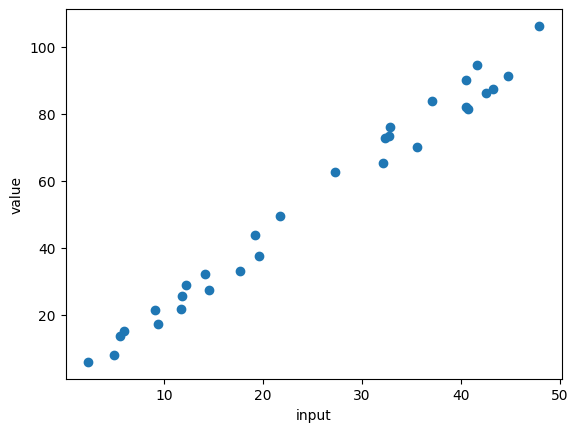

In [37]:
import matplotlib.pyplot as plt
# print(data.input,data.value)
# 绘制散点图
plt.scatter(data.input,data.value)
plt.xlabel('input')
plt.ylabel('value')
plt.show()

In [38]:
# 将pandas数据转换为pytorch的数据（张量）
X= torch.from_numpy(data.input.to_numpy().reshape(-1,1)).float()
X

tensor([[32.3319],
        [14.4764],
        [37.0871],
        [44.7168],
        [21.6742],
        [11.7133],
        [ 2.3003],
        [32.8443],
        [11.8016],
        [40.6621],
        [40.4851],
        [17.6723],
        [47.9034],
        [ 5.5445],
        [42.5272],
        [40.5493],
        [27.2752],
        [19.5482],
        [41.6408],
        [43.2236],
        [35.5240],
        [12.1670],
        [ 4.9098],
        [ 5.9491],
        [32.1485],
        [19.1389],
        [14.0819],
        [32.7537],
        [ 9.3858],
        [ 9.0067]])

In [39]:
Y= torch.from_numpy(data.value.to_numpy().reshape(-1,1)).float()
Y

tensor([[ 72.8241],
        [ 27.3915],
        [ 83.7528],
        [ 91.2053],
        [ 49.5527],
        [ 21.8743],
        [  5.9612],
        [ 76.1192],
        [ 25.7339],
        [ 81.3265],
        [ 90.1752],
        [ 33.2271],
        [106.2744],
        [ 13.7596],
        [ 86.1539],
        [ 82.0967],
        [ 62.7158],
        [ 37.4812],
        [ 94.5177],
        [ 87.3629],
        [ 70.2583],
        [ 28.9951],
        [  8.1247],
        [ 15.3368],
        [ 65.3794],
        [ 43.8825],
        [ 32.1693],
        [ 73.4418],
        [ 17.2569],
        [ 21.5874]])

In [40]:
X.size()

torch.Size([30, 1])

In [41]:
# 导入专门用于搭建神经网络的模型
from torch import nn

class EasyModel(nn.Module):
    # 初始化模型实现1层线性网络
    def __init__(self):
        # 调用父类进行初始化
        super(EasyModel,self).__init__()
        # 定义中间的一层线性层，输出输入维度都是1
        self.linear = nn.Linear(in_features=1,out_features=1)

    # 定义1个前向传播函数，告诉模型如何一层层往下输出的逻辑
    def forward(self,inputs):
        # 设置将输入的input，输入到线性层
        logits = self.linear(inputs)
        return logits

# 实例化一个模型，用于训练和预测
model = EasyModel()

# 定义均方误差为损失函数
loss_fn = nn.MSELoss()


In [42]:
# 定义优化器，设置模型参数进来，让优化器修改模型参数，使得误差更小。lr，学习率，调节学习快慢。越慢越详细，稳定
opt = torch.optim.SGD(model.parameters(),lr=0.0001)

In [43]:
# 训练
for epoch in range(5000):
    for x,y in zip(X,Y):
        # 先让模型做预测
        y_pred = model(x)
        # 预测了，看看误差怎么样，计算损失函数
        loss=loss_fn(y,y_pred)
        # 复原，梯度归零
        opt.zero_grad()
        # 根据误差，倒退怎么修改参数，反向传播
        loss.backward()
        # 使用优化器，更新参数
        opt.step()

In [47]:
# list(zip(X,Y))

In [50]:
# 预测结果
# detach用于前向传播计算
Y_pred = model(X).detach()

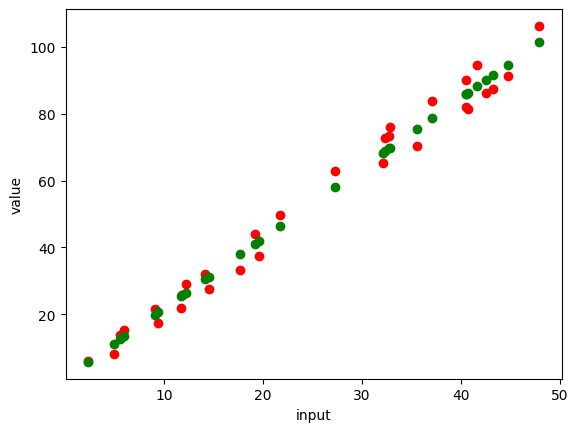

In [51]:
# 绘制散点图
plt.scatter(data.input,data.value,c='r',label='real data')
plt.scatter(data.input,Y_pred,c='g',label='pred data')
plt.xlabel('input')
plt.ylabel('value')
plt.show()